## Ćwiczenie 10: Region growing - rzeczywisty obraz medyczny (MRI)

## Cel ćwiczenia
Zastosujemy opracowaną funkcję do **rzeczywistego skanu z rezonansu magnetycznego (MRI)** głowy.

Przekonasz się, że praca z prawdziwymi danymi medycznymi kryje w sobie nowe wyzwania:
* **Brak ostrych krawędzi:** Granice między tkankami bywają płynne ze względu na rozdzielczość sprzętu.
* **Niejednorodność pola (Bias Field):** Ta sama struktura może mieć nieco inną jasność po lewej i po prawej stronie skanu (artefakty cewki magnetycznej).
* **Szum:** Rzeczywisty szum ma bardziej skomplikowaną strukturę niż prosty szum Gaussa.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from skimage import data, filters, measure, exposure

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


In [4]:
# Funkcja Region Growing z poprzednich ćwiczeń
def region_growing(img, seed, threshold):
    height, width = img.shape
    segmented = np.zeros((height, width), dtype=bool)
    visited = np.zeros((height, width), dtype=bool)
    
    seed_y, seed_x = seed
    seed_val = float(img[seed_y, seed_x])
    
    queue = deque([(seed_y, seed_x)])
    visited[seed_y, seed_x] = True
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    
    while queue:
        y, x = queue.popleft()
        segmented[y, x] = True
        
        for dy, dx in neighbors:
            ny, nx = y + dy, x + dx
            if 0 <= ny < height and 0 <= nx < width:
                if not visited[ny, nx]:
                    visited[ny, nx] = True
                    if abs(float(img[ny, nx]) - seed_val) <= threshold:
                        queue.append((ny, nx))
    return segmented

### Wczytanie i eksploracja obrazu MRI
Wczytamy przekrój mózgu. Spróbuj najechać kursorem (lub popatrzeć na osie X i Y), aby znaleźć odpowiednie współrzędne `(y, x)` dla **komór mózgu** (charakterystyczne, ciemne, przypominające motyla obszary w centrum skanu wypełnione płynem mózgowo-rdzeniowym) lub dla **jasnej istoty białej**.

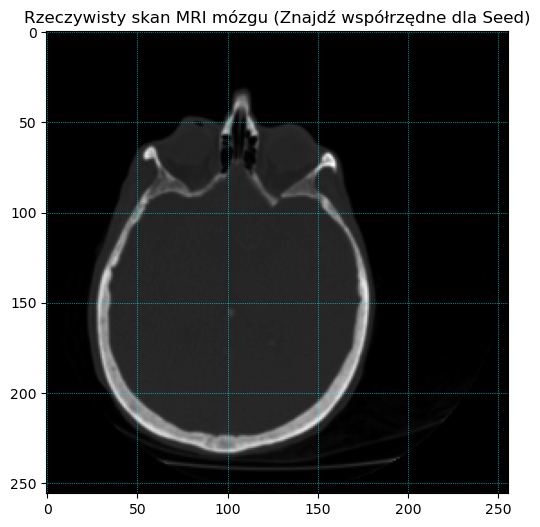

In [17]:
# Próbujemy załadować wbudowany w skimage obraz MRI, a w razie braku - pobieramy obraz awaryjny
try:
    mri_volume = data.brain()
    # Wybieramy jeden ze środkowych przekrojów
    real_mri = mri_volume[5, :, :]
except AttributeError:
    from skimage import io
    # Pobranie przykładowego skanu T1 z domeny publicznej (gdy brakuje danych w lokalnej wersji skimage)
    url = "https://upload.wikimedia.org/wikipedia/commons/thumb/c/c5/Brain_MRI_Slice.png/256px-Brain_MRI_Slice.png"
    real_mri = io.imread(url, as_gray=True)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(real_mri, cmap='gray')
ax.set_title("Rzeczywisty skan MRI mózgu (Znajdź współrzędne dla Seed)")
plt.grid(color='cyan', linestyle=':', linewidth=0.5)
plt.show()

### Zadanie: Segmentacja komory bocznej

Twoim zadaniem jest wysegmentowanie komory mózgowej (ciemnego obszaru wewnątrz mózgu). 
1. Przyjrzyj się obrazkowi wyżej i odczytaj z osi współrzędne `(y, x)` znajdujące się wewnątrz tego obszaru.
2. Przefiltruj obraz. Zwykłe rozmycie Gaussa usunie szum, ale może też zatrzeć delikatne krawędzie komory.
3. Poeksperymentuj z wartością progu `threshold`.

**Pytanie do przemyślenia:** Dlaczego przy odrobinie zbyt wysokim progu, maska "wylewa się" przez cienkie połączenia do innych obszarów i jak można temu zapobiec?

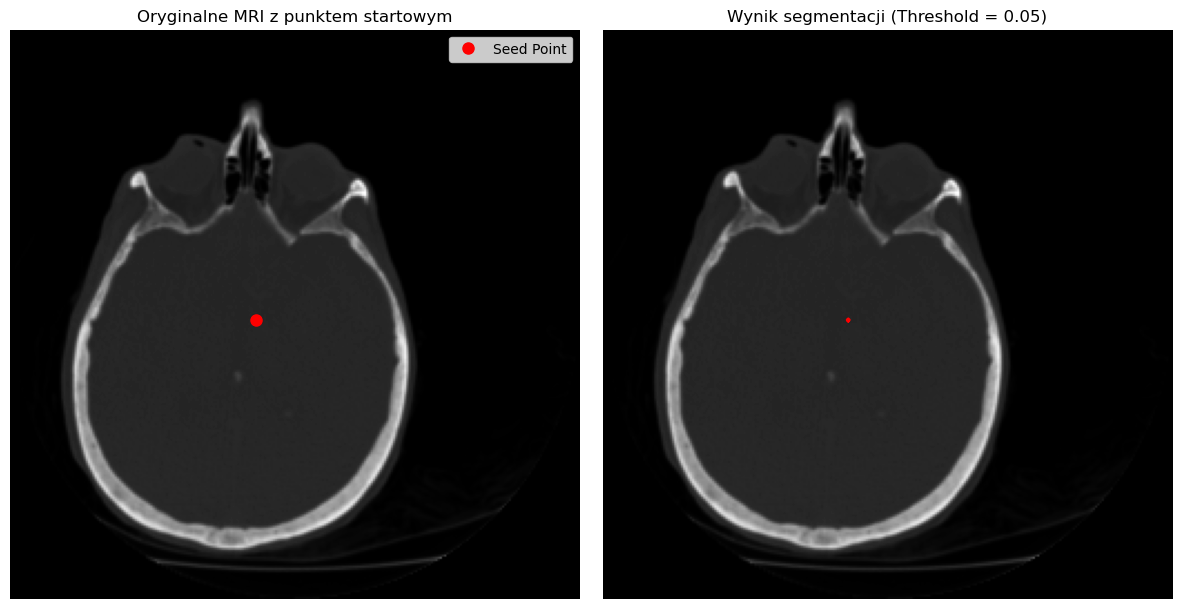

In [20]:
# TODO: Odczytaj współrzędne (pion - oś Y, poziom - oś X) dla punktu startowego
seed_point = (130, 110)  # Przykładowe miejsce (zmień jeśli trzeba)

# TODO: Przefiltruj zdjęcie przed segmentacją
filtered_mri = real_mri  # Dodaj filtrację, np. filters.gaussian(real_mri, sigma=1.0)

# TODO: Dobierz rygorystyczny próg jasności dla rzeczywistego obrazu
threshold_val = 0.05 

# Uruchomienie algorytmu
ventricle_mask = region_growing(filtered_mri, seed_point, threshold_val)

# Wyświetlanie wyników
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(real_mri, cmap='gray')
axes[0].plot(seed_point[1], seed_point[0], 'ro', markersize=8, label='Seed Point')
axes[0].legend()
axes[0].set_title("Oryginalne MRI z punktem startowym")
axes[0].axis('off')

axes[1].imshow(real_mri, cmap='gray')
contours = measure.find_contours(ventricle_mask, 0.5)
for contour in contours:
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')
axes[1].set_title(f"Wynik segmentacji (Threshold = {threshold_val})")
axes[1].axis('off')

plt.tight_layout()
plt.show()